# ATFM Analysis on European airports (2019–2026)

In this project I intend to discover how much of Europe's  dealy comes from ATFM and which airport suffer the most by answering to the following questions:

  1. What share of departure delay is caused by local ATC?
  2. Which airports are hit hardest by arrival ATFM delay, and when (season, weekday, traffic level)?
  3. Does ATFM slot adherence get worse when delay is high?
  4. Can we forecast an airport's daily arrival ATFM delay one week ahead?

**Data:** EUROCONTROL Aviation Intelligence Portal, https://ansperformance.eu/data/
- Airport traffic (daily, per airport)
- Airport arrival ATFM delay (daily, per airport, by delay cause)
- All-causes pre-departure delay (daily, per airport)
- ATC pre-departure delay (daily, per airport)
- ATFM slot adherence (daily, per airport)

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# Set paths relative to the notebook using the extracted folder structure
RAW = Path("data_atfm/raw")
PROCESSED = Path("data_atfm/processed")
IMAGES = Path("data_atfm/images")

# Ensure output folders exist
for folder in (PROCESSED, IMAGES):
    folder.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_columns", None)
print(RAW, "->", len(list(RAW.glob("*"))), "files found")

Matplotlib is building the font cache; this may take a moment.


data_atfm\raw -> 50 files found


Each dataset is split into one file per year.

In [2]:
def load_dataset(pattern):
    files = sorted(RAW.glob(pattern))
    # encoding_errors="replace": a few source files mix text encodings (see section 3)
    df = pd.concat([pd.read_csv(f, encoding_errors="replace") for f in files], ignore_index=True)
    print(f"{pattern}: {len(files)} files, {len(df):,} rows, {df.shape[1]} columns")
    return df

## 1. Load the five datasets

In [3]:
traffic = load_dataset("airport_traffic_*.csv")
arr_dly = load_dataset("apt_dly_*.csv.bz2")          # .bz2 = compressed, pandas reads it directly
pre_all = load_dataset("all_pre_departure_delays_*.csv")
pre_atc = load_dataset("atc_pre_departure_delays_*.csv")
slot = load_dataset("atfm_slot_adherence_*.csv")

tables = {"traffic": traffic, "arr_dly": arr_dly, "pre_all": pre_all, "pre_atc": pre_atc, "slot": slot}

airport_traffic_*.csv: 11 files, 1,216,402 rows, 13 columns
apt_dly_*.csv.bz2: 13 files, 1,258,145 rows, 28 columns
all_pre_departure_delays_*.csv: 7 files, 756,441 rows, 10 columns
atc_pre_departure_delays_*.csv: 8 files, 870,347 rows, 12 columns
atfm_slot_adherence_*.csv: 11 files, 1,070,367 rows, 12 columns


## 2. First look at each table

One row = one airport on one day. Suffix `_1` = Network Manager data, `_2` = airport operator data (only some airports report it).

In [4]:
traffic.head()

,YEAR,MONTH_NUM,MONTH_MON,FLT_DATE,APT_ICAO,APT_NAME,STATE_NAME,FLT_DEP_1,FLT_ARR_1,FLT_TOT_1,FLT_DEP_IFR_2,FLT_ARR_IFR_2,FLT_TOT_IFR_2
0,2016,1,JAN,2016-01-01,LATI,Tirana,Albania,24,27,51,NaN,NaN,NaN
1,2016,1,JAN,2016-01-01,UDYZ,Yerevan,Armenia,8,15,23,NaN,NaN,NaN
2,2016,1,JAN,2016-01-01,LOWG,Graz,Austria,6,7,13,NaN,NaN,NaN
3,2016,1,JAN,2016-01-01,LOWI,Innsbruck,Austria,26,32,58,NaN,NaN,NaN
4,2016,1,JAN,2016-01-01,LOWK,Klagenfurt,Austria,3,4,7,NaN,NaN,NaN


In [5]:
arr_dly.head()

,YEAR,MONTH_NUM,MONTH_MON,FLT_DATE,APT_ICAO,APT_NAME,STATE_NAME,FLT_ARR_1,DLY_APT_ARR_1,DLY_APT_ARR_A_1,DLY_APT_ARR_C_1,DLY_APT_ARR_D_1,DLY_APT_ARR_E_1,DLY_APT_ARR_G_1,DLY_APT_ARR_I_1,DLY_APT_ARR_M_1,DLY_APT_ARR_N_1,DLY_APT_ARR_O_1,DLY_APT_ARR_P_1,DLY_APT_ARR_R_1,DLY_APT_ARR_S_1,DLY_APT_ARR_T_1,DLY_APT_ARR_V_1,DLY_APT_ARR_W_1,DLY_APT_ARR_NA_1,FLT_ARR_1_DLY,FLT_ARR_1_DLY_15,ATFM_VERSION
0,2014,1,JAN,2014-01-01T00:00:00Z,LGRP,Rodos,Greece,10,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,v1
1,2014,1,JAN,2014-01-01T00:00:00Z,LFLP,Annecy-Meythet,France,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,v1
2,2014,1,JAN,2014-01-01T00:00:00Z,LFPG,Paris-Charles-de-Gaulle,France,509,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,v1
3,2014,1,JAN,2014-01-01T00:00:00Z,EPRZ,Rzeszow - Jasionka,Poland,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,v1
4,2014,1,JAN,2014-01-01T00:00:00Z,GCXO,Tenerife North,Spain,55,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,v1


In [6]:
pre_all.head()

,YEAR,MONTH_NUM,MONTH_MON,FLT_DATE,APT_ICAO,APT_NAME,STATE_NAME,FLT_DEP_1,FLT_DEP_IFR_2,DLY_ALL_PRE_2
0,2020,1,JAN,2020-01-01,LATI,Tirana,Albania,34,NaN,NaN
1,2020,1,JAN,2020-01-01,UDYZ,Yerevan,Armenia,37,NaN,NaN
2,2020,1,JAN,2020-01-01,LOWG,Graz,Austria,8,NaN,NaN
3,2020,1,JAN,2020-01-01,LOWI,Innsbruck,Austria,19,NaN,NaN
4,2020,1,JAN,2020-01-01,LOWK,Klagenfurt,Austria,6,NaN,NaN


In [7]:
pre_atc.head()

,YEAR,MONTH_NUM,MONTH_MON,FLT_DATE,APT_ICAO,APT_NAME,STATE_NAME,FLT_DEP_1,FLT_DEP_IFR_2,DLY_ATC_PRE_2,FLT_DEP_3,DLY_ATC_PRE_3
0,2019,1,JAN,2019-01-01,EBAW,Antwerp,Belgium,7,NaN,NaN,3.0,0.0
1,2019,1,JAN,2019-01-01,EBBR,Brussels,Belgium,214,214.0,95.0,172.0,66.0
2,2019,1,JAN,2019-01-01,EBCI,Charleroi,Belgium,53,53.0,0.0,50.0,12.0
3,2019,1,JAN,2019-01-01,EBLG,Liège,Belgium,14,NaN,NaN,6.0,0.0
4,2019,1,JAN,2019-01-01,EBOS,Ostend-Bruges,Belgium,7,NaN,NaN,2.0,0.0


In [8]:
slot.head()

,YEAR,MONTH_NUM,MONTH_MON,FLT_DATE,APT_ICAO,APT_NAME,STATE_NAME,FLT_DEP_1,FLT_DEP_REG_1,FLT_DEP_OUT_EARLY_1,FLT_DEP_IN_1,FLT_DEP_OUT_LATE_1
0,2016,1,JAN,2016-01-01,EBAW,Antwerp,Belgium,4,2,0,2,0
1,2016,1,JAN,2016-01-01,EBBR,Brussels,Belgium,174,41,0,40,1
2,2016,1,JAN,2016-01-01,EBCI,Charleroi,Belgium,45,12,0,11,1
3,2016,1,JAN,2016-01-01,EBLG,Liège,Belgium,6,0,0,0,0
4,2016,1,JAN,2016-01-01,EBOS,Ostend-Bruges,Belgium,7,3,0,3,0


`info()` shows each column's type and how many non-empty values it has. Columns with far fewer non-null values than rows have a lot of missing data.

In [9]:
arr_dly.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1258145 entries, 0 to 1258144
Data columns (total 28 columns):
 #   Column            Non-Null Count    Dtype  
---  ------            --------------    -----  
 0   YEAR              1258145 non-null  int64  
 1   MONTH_NUM         1258145 non-null  int64  
 2   MONTH_MON         1258145 non-null  object 
 3   FLT_DATE          1258145 non-null  object 
 4   APT_ICAO          1258145 non-null  object 
 5   APT_NAME          1258145 non-null  object 
 6   STATE_NAME        1258145 non-null  object 
 7   FLT_ARR_1         1258145 non-null  int64  
 8   DLY_APT_ARR_1     428962 non-null   float64
 9   DLY_APT_ARR_A_1   428962 non-null   float64
 10  DLY_APT_ARR_C_1   428962 non-null   float64
 11  DLY_APT_ARR_D_1   428962 non-null   float64
 12  DLY_APT_ARR_E_1   428962 non-null   float64
 13  DLY_APT_ARR_G_1   428962 non-null   float64
 14  DLY_APT_ARR_I_1   428962 non-null   float64
 15  DLY_APT_ARR_M_1   428962 non-null   float64
 16  

## 3. Cleaning

**Broken characters.** In `apt_dly_2025` and `apt_dly_2026` the country name "Türkiye" is stored in a different text encoding than the rest of the file, so it loads as `T�rkiye '; therefore, it needs to be repaired:

In [10]:
arr_dly["STATE_NAME"] = arr_dly["STATE_NAME"].replace("T\ufffdrkiye", "Türkiye")

for name, df in tables.items():
    text_cols = df.select_dtypes(include=["object", "string"])
    broken = text_cols.apply(lambda col: col.astype(str).str.contains("\ufffd")).sum().sum()
    print(name, "broken cells:", broken)

traffic broken cells: 0
arr_dly broken cells: 0
pre_all broken cells: 0
pre_atc broken cells: 0
slot broken cells: 0


**Dates.** The files write dates differently (`2025-01-01` vs `2025-01-01T00:00:00Z`). Keeping only the first 10 characters (`YYYY-MM-DD`) makes them identical, then `to_datetime` turns the text into real dates.

In [11]:
for df in tables.values():
    df["FLT_DATE"] = pd.to_datetime(df["FLT_DATE"].astype(str).str[:10])

**Duplicates.** Each table should have exactly one row per airport per day. Check it:

In [12]:
KEYS = ["FLT_DATE", "APT_ICAO"]
for name, df in tables.items():
    print(name, "duplicate date+airport rows:", df.duplicated(KEYS).sum())

traffic duplicate date+airport rows: 1
arr_dly duplicate date+airport rows: 0
pre_all duplicate date+airport rows: 0
pre_atc duplicate date+airport rows: 0
slot duplicate date+airport rows: 0


In [13]:
# The traffic table has one exact duplicate (Antwerp, 1 Jan 2022): every column is identical, so drop it
print(traffic[traffic.duplicated(KEYS, keep=False)][KEYS + ["FLT_TOT_1"]])
traffic.drop_duplicates(subset=KEYS, inplace=True)
print("duplicates left:", traffic.duplicated(KEYS).sum())

         FLT_DATE APT_ICAO  FLT_TOT_1
640884 2022-01-01     EBAW         17
640885 2022-01-01     EBAW         17
duplicates left: 0


## 4. Overview: period and airports covered

In [14]:
overview = pd.DataFrame({
    name: {
        "first_date": df["FLT_DATE"].min().date(),
        "last_date": df["FLT_DATE"].max().date(),
        "airports": df["APT_ICAO"].nunique(),
        "rows": len(df),
    }
    for name, df in tables.items()
}).T
overview

,first_date,last_date,airports,rows
traffic,2016-01-01,2026-08-31,380,1216401
arr_dly,2014-01-01,2026-08-31,293,1258145
pre_all,2020-01-01,2026-08-31,334,756441
pre_atc,2019-01-01,2026-08-31,334,870347
slot,2016-01-01,2026-10-14,292,1070367


## 5. Missing values

Share of empty cells per column (only columns that have any). This tells us which measures we can trust for which airports.

In [15]:
for name, df in tables.items():
    missing = df.isna().mean().round(3)
    print(f"--- {name}")
    print(missing[missing > 0].sort_values(ascending=False).to_string(), "\n")

--- traffic
FLT_DEP_IFR_2    0.712
FLT_ARR_IFR_2    0.712
FLT_TOT_IFR_2    0.712 

--- arr_dly
DLY_APT_ARR_1       0.659
DLY_APT_ARR_P_1     0.659
FLT_ARR_1_DLY       0.659
DLY_APT_ARR_NA_1    0.659
DLY_APT_ARR_W_1     0.659
DLY_APT_ARR_V_1     0.659
DLY_APT_ARR_T_1     0.659
DLY_APT_ARR_S_1     0.659
DLY_APT_ARR_R_1     0.659
DLY_APT_ARR_O_1     0.659
DLY_APT_ARR_A_1     0.659
DLY_APT_ARR_N_1     0.659
DLY_APT_ARR_M_1     0.659
DLY_APT_ARR_I_1     0.659
DLY_APT_ARR_G_1     0.659
DLY_APT_ARR_E_1     0.659
DLY_APT_ARR_D_1     0.659
DLY_APT_ARR_C_1     0.659
FLT_ARR_1_DLY_15    0.659 

--- pre_all
FLT_DEP_IFR_2    0.719
DLY_ALL_PRE_2    0.719 

--- pre_atc
FLT_DEP_IFR_2    0.795
DLY_ATC_PRE_2    0.795
FLT_DEP_3        0.274
DLY_ATC_PRE_3    0.274 

--- slot
Series([], ) 



### Empty arrival delay = no delay

About 66% of the arrival-delay values are empty. Checking by year shows why: up to 2022 the files leave the cell empty when an airport had no ATFM delay that day, and from 2023 they write 0 instead.

In [16]:
arr_dly.groupby("YEAR").agg(
    share_empty=("DLY_APT_ARR_1", lambda s: s.isna().mean().round(3)),
    zeros=("DLY_APT_ARR_1", lambda s: (s == 0).sum()),
)

,share_empty,zeros
YEAR,,
2014,0.942,211
2015,0.931,453
2016,0.920,214
2017,0.913,243
2018,0.908,363
2019,0.910,300
2020,0.978,212
2021,0.969,178
2022,0.933,284


In [17]:
# all delay columns (DLY_APT_ARR_...) and delayed-flight counts (FLT_ARR_1_DLY...): empty -> 0
delay_cols = [c for c in arr_dly.columns if c.startswith("DLY_APT_ARR") or c.startswith("FLT_ARR_1_DLY")]
arr_dly[delay_cols] = arr_dly[delay_cols].fillna(0)

print("empty delay values left:", arr_dly[delay_cols].isna().sum().sum())

empty delay values left: 0


The empty `_2` columns in the traffic and pre-departure tables are different: they are really missing, because only some airports report their own (airport operator) data. We keep them empty and later restrict the analysis to airports that report.


- **Coverage:** traffic runs from Jan 2016 to Aug 2026 (380 airports) and arrival ATFM delay from Jan 2014 to Aug 2026 (293 airports). Pre-departure delay starts later: ATC (code 89) in 2019 and all causes in 2020 (334 airports). Slot adherence covers Jan 2016 to mid-Oct 2026 (292 airports).
- **Empty columns:** the airport-operator columns (`_2`) are 71–79% empty, because only some airports report them. The airline-reported ATC delay (`_3`) is only 27% empty, so I use it for the ATC analysis.
- **Cleaning:** empty arrival-delay cells up to 2022 mean zero delay (from 2023 the files write 0), so I filled them with 0.


## 6. Choose the airports

Analysing all ~380 airports would be noisy. I focus on the 10 busiest airports in 2025 (the last full year), plus Bucharest Henri Coandă (LROP).

In [18]:
busiest = (traffic[traffic["FLT_DATE"].dt.year == 2025]
           .groupby(["APT_ICAO", "APT_NAME"])["FLT_TOT_1"].sum()
           .sort_values(ascending=False))
busiest.head(15)

APT_ICAO  APT_NAME                 
LTFM      Istanbul                     544121
EHAM      Amsterdam - Schiphol         493042
EGLL      London - Heathrow            480072
LFPG      Paris - Charles-de-Gaulle    479761
EDDF      Frankfurt                    460295
LEMD      Madrid - Barajas             430785
LEBL      Barcelona                    360831
EDDM      Munich                       334833
LIRF      Rome - Fiumicino             322766
LGAV      Athens                       278241
LSZH      Zürich                       267710
LTFJ      Istanbul - Sabiha Gökçen     265254
EGKK      London - Gatwick             263105
EKCH      Copenhagen - Kastrup         256659
EIDW      Dublin                       255290
Name: FLT_TOT_1, dtype: int64

In [19]:
AIRPORTS = list(busiest.head(10).index.get_level_values("APT_ICAO"))
if "LROP" not in AIRPORTS:
    AIRPORTS.append("LROP")
print(AIRPORTS)

['LTFM', 'EHAM', 'EGLL', 'LFPG', 'EDDF', 'LEMD', 'LEBL', 'EDDM', 'LIRF', 'LGAV', 'LROP']


## 7. Pre-departure delay: 

Pre-departure delay is the delay a flight takes at the stand before it leaves. Two datasets describe it:

- **All causes:** `DLY_ALL_PRE_2`, reported by the **airport operator** (`_2`), for `FLT_DEP_IFR_2` departures.
- **ATC (IATA code 89):** the delay at the stand caused by *local* ATC at the departure airport (e.g. waiting for start-up or push-back approval to avoid queues at the runway). It is **not** the ATFM slot delay (codes 81–84). The file has two versions: `DLY_ATC_PRE_2` from the airport operator and `DLY_ATC_PRE_3` from the **airlines** (CODA), for `FLT_DEP_3` departures.

How many days does each source cover at my airports?

In [20]:
focus_pre_all = pre_all[pre_all["APT_ICAO"].isin(AIRPORTS)]
focus_pre_atc = pre_atc[pre_atc["APT_ICAO"].isin(AIRPORTS)]

coverage = pd.DataFrame({
    "all_causes (airport)": focus_pre_all.groupby("APT_ICAO")["DLY_ALL_PRE_2"].count(),
    "ATC code 89 (airport)": focus_pre_atc.groupby("APT_ICAO")["DLY_ATC_PRE_2"].count(),
    "ATC code 89 (airlines)": focus_pre_atc.groupby("APT_ICAO")["DLY_ATC_PRE_3"].count(),
}).reindex(AIRPORTS)
coverage

,all_causes (airport),ATC code 89 (airport),ATC code 89 (airlines)
APT_ICAO,,,
LTFM,2038,0,2733
EHAM,2402,0,2769
EGLL,2427,0,2768
LFPG,2404,214,2769
EDDF,2435,2344,2770
LEMD,2402,273,2768
LEBL,2402,488,2770
EDDM,2400,2400,2766
LIRF,2404,2769,2769


The airport-reported ATC column is empty for Istanbul, Amsterdam and Heathrow and sparse for Paris, Madrid and Barcelona. The airline-reported version (`_3`) covers every airport on almost every day, so I use it.

Because the two measures come from different reporters and cover a different number of flights, I don't divide minutes by minutes. I compare minutes per departure from each source:

- total pre-departure delay per departure = `DLY_ALL_PRE_2 / FLT_DEP_IFR_2`
- code-89 delay per departure = `DLY_ATC_PRE_3 / FLT_DEP_3`
- code-89 share ≈ code-89 per departure ÷ total per departure

Limitation: the share mixes two reporting sources, so read it as an estimate, not an exact percentage.

## 8. Merge into one daily table

One row per airport per day, from 2019, with only the columns I need from each of the five tables. (Duplicates were already checked in section 3.)

In [21]:
# arrival ATFM delay split by cause: DLY_APT_ARR_C_1, DLY_APT_ARR_S_1, ...
cause_cols = [c for c in arr_dly.columns
              if c.startswith("DLY_APT_ARR_") and c.endswith("_1") and c != "DLY_APT_ARR_1"]

daily = (
    traffic.loc[traffic["APT_ICAO"].isin(AIRPORTS),
                KEYS + ["APT_NAME", "FLT_DEP_1", "FLT_ARR_1", "FLT_TOT_1"]]
    .merge(arr_dly[KEYS + ["DLY_APT_ARR_1"] + cause_cols], on=KEYS, how="left")
    .merge(pre_all[KEYS + ["FLT_DEP_IFR_2", "DLY_ALL_PRE_2"]], on=KEYS, how="left")
    .merge(pre_atc[KEYS + ["FLT_DEP_3", "DLY_ATC_PRE_3"]], on=KEYS, how="left")
    .merge(slot[KEYS + ["FLT_DEP_REG_1", "FLT_DEP_OUT_EARLY_1", "FLT_DEP_IN_1", "FLT_DEP_OUT_LATE_1"]],
           on=KEYS, how="left")
)
daily = daily[daily["FLT_DATE"] >= "2019-01-01"].copy()
daily["year"] = daily["FLT_DATE"].dt.year

print(daily.shape)
print("days with no arrival-delay row:", daily["DLY_APT_ARR_1"].isna().sum())
daily.head()

(30800, 32)
days with no arrival-delay row: 0


,FLT_DATE,APT_ICAO,APT_NAME,FLT_DEP_1,FLT_ARR_1,FLT_TOT_1,DLY_APT_ARR_1,DLY_APT_ARR_A_1,DLY_APT_ARR_C_1,DLY_APT_ARR_D_1,DLY_APT_ARR_E_1,DLY_APT_ARR_G_1,DLY_APT_ARR_I_1,DLY_APT_ARR_M_1,DLY_APT_ARR_N_1,DLY_APT_ARR_O_1,DLY_APT_ARR_P_1,DLY_APT_ARR_R_1,DLY_APT_ARR_S_1,DLY_APT_ARR_T_1,DLY_APT_ARR_V_1,DLY_APT_ARR_W_1,DLY_APT_ARR_NA_1,FLT_DEP_IFR_2,DLY_ALL_PRE_2,FLT_DEP_3,DLY_ATC_PRE_3,FLT_DEP_REG_1,FLT_DEP_OUT_EARLY_1,FLT_DEP_IN_1,FLT_DEP_OUT_LATE_1,year
11024,2019-01-01,LFPG,Paris-Charles-de-Gaulle,579,573,1152,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,478.0,153.0,54.0,1.0,51.0,2.0,2019
11025,2019-01-01,EDDF,Frankfurt,473,417,890,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,386.0,54.0,27.0,7.0,20.0,0.0,2019
11026,2019-01-01,EDDM,Munich,357,322,679,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,305.0,8.0,19.0,0.0,19.0,0.0,2019
11027,2019-01-01,LGAV,Athens,182,178,360,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,122.0,27.0,6.0,0.0,6.0,0.0,2019
11028,2019-01-01,LIRF,Rome - Fiumicino,356,336,692,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,295.0,210.0,20.0,0.0,19.0,1.0,2019


In [22]:
daily.to_csv(PROCESSED / "daily_focus_airports.csv", index=False)

A helper for every rate in this notebook. It sums minutes and flights first and divides once (a ratio of sums), so a quiet day with one delayed flight doesn't weigh as much as a busy summer day. Days where either value is missing are skipped.

In [23]:
def rate(df, minutes, flights, by):
    ok = df.dropna(subset=[minutes, flights])
    ok = ok[ok[flights] > 0]
    sums = ok.groupby(by)[[minutes, flights]].sum()
    return sums[minutes] / sums[flights]

YEAR_LABELS = {2026: "2026*"}   # 2026 only runs to August

## 9. Q1: How much pre-departure delay is caused by local ATC?

In [24]:
pre_total = rate(daily, "DLY_ALL_PRE_2", "FLT_DEP_IFR_2", ["APT_ICAO", "year"]).unstack("year")
pre_atc89 = rate(daily, "DLY_ATC_PRE_3", "FLT_DEP_3", ["APT_ICAO", "year"]).unstack("year")

atc_share = (pre_atc89 / pre_total * 100).loc[:, 2020:]   # all-causes data starts in 2020
print("Total pre-departure delay, minutes per departure")
display(pre_total.round(1))
print("Code-89 ATC share of pre-departure delay, %")
display(atc_share.round(1))

Total pre-departure delay, minutes per departure


year,2020,2021,2022,2023,2024,2025,2026
APT_ICAO,,,,,,,
EDDF,16.5,20.4,27.9,25.8,23.2,18.9,18.1
EDDM,7.3,9.0,16.7,18.4,19.7,12.8,12.3
EGLL,8.9,11.5,21.4,19.0,16.6,12.4,12.2
EHAM,15.5,20.4,27.3,24.0,21.2,19.6,19.0
LEBL,8.7,8.3,15.8,17.1,19.0,16.7,16.7
LEMD,9.5,9.7,13.1,14.9,16.6,16.5,16.9
LFPG,12.9,17.1,21.3,22.5,20.6,19.5,18.2
LGAV,8.0,12.9,17.4,18.6,19.5,18.8,17.7
LIRF,6.4,9.2,14.9,17.3,18.9,14.3,14.1


Code-89 ATC share of pre-departure delay, %


year,2020,2021,2022,2023,2024,2025,2026
APT_ICAO,,,,,,,
EDDF,3.3,2.0,1.9,2.7,3.0,3.6,2.2
EDDM,0.8,2.1,0.7,1.0,1.0,2.7,1.8
EGLL,4.4,5.2,6.7,11.1,13.9,15.8,12.5
EHAM,6.8,4.6,5.6,8.0,10.9,12.2,10.4
LEBL,3.1,3.6,4.5,5.9,4.7,4.5,5.0
LEMD,5.3,3.6,4.4,6.9,6.9,6.1,5.1
LFPG,3.7,3.6,4.3,3.4,4.0,5.0,4.7
LGAV,3.7,4.8,6.3,5.3,9.4,14.4,11.2
LIRF,8.7,7.7,9.7,9.7,9.6,10.5,9.6


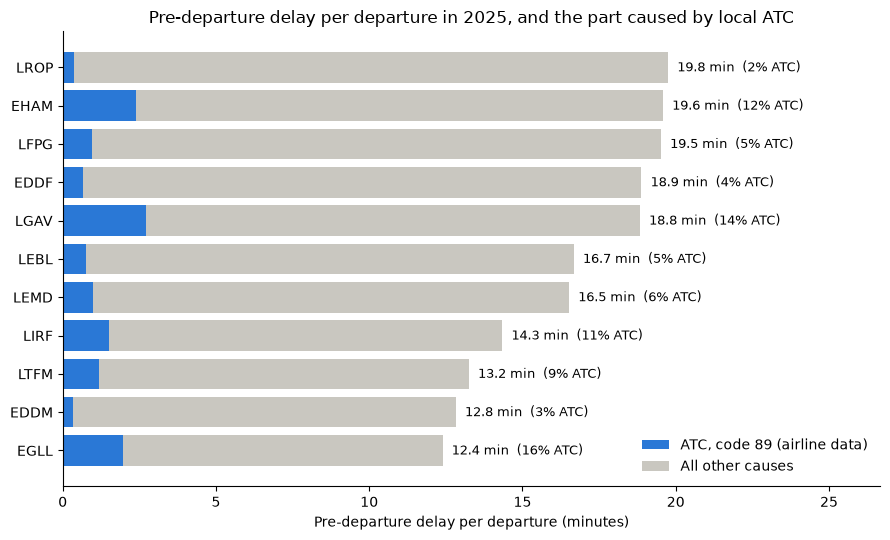

In [25]:
# 2025: split each airport's pre-departure delay per departure into code 89 and everything else
y25 = pd.DataFrame({"ATC (code 89)": pre_atc89[2025],
                    "All other causes": pre_total[2025] - pre_atc89[2025]})
y25 = y25.loc[pre_total[2025].sort_values().index]

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(y25.index, y25["ATC (code 89)"], color="#2a78d6", label="ATC, code 89 (airline data)")
ax.barh(y25.index, y25["All other causes"], left=y25["ATC (code 89)"], color="#c9c7c0",
        label="All other causes")
for i, (apt, row) in enumerate(y25.iterrows()):
    share = row["ATC (code 89)"] / row.sum() * 100
    ax.text(row.sum() + 0.3, i, f"{row.sum():.1f} min  ({share:.0f}% ATC)", va="center", fontsize=9)
ax.set_xlabel("Pre-departure delay per departure (minutes)")
ax.set_xlim(0, y25.sum(axis=1).max() * 1.35)
ax.set_title("Pre-departure delay per departure in 2025, and the part caused by local ATC")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(loc="lower right", frameon=False)
plt.tight_layout()
plt.savefig(IMAGES / "pre_departure_2025.png", dpi=150)
plt.show()

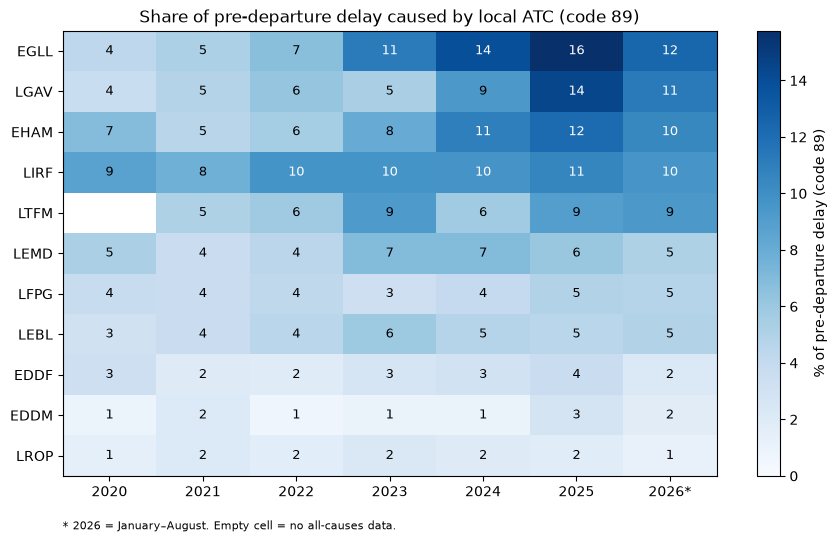

In [26]:
fig, ax = plt.subplots(figsize=(9, 5.5))
shown = atc_share.loc[atc_share[2025].sort_values(ascending=False).index]
im = ax.imshow(shown.values, cmap="Blues", aspect="auto", vmin=0)
ax.set_xticks(range(shown.shape[1]), [YEAR_LABELS.get(y, y) for y in shown.columns])
ax.set_yticks(range(shown.shape[0]), shown.index)
for i in range(shown.shape[0]):
    for j in range(shown.shape[1]):
        v = shown.values[i, j]
        if pd.notna(v):
            ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=9,
                    color="white" if v > shown.max().max() * 0.6 else "black")
fig.colorbar(im, label="% of pre-departure delay (code 89)")
ax.set_title("Share of pre-departure delay caused by local ATC (code 89)")
ax.text(0, -0.12, "* 2026 = January–August. Empty cell = no all-causes data.",
        transform=ax.transAxes, fontsize=8)
plt.tight_layout()
plt.savefig(IMAGES / "atc_share_heatmap.png", dpi=150)
plt.show()

### What this shows

Local ATC (code 89) causes only a small part of pre-departure delay: 1–16% depending on the airport, so most delay at the stand has other causes. Three airports stand out, and the share rose sharply at each since 2020: Heathrow went from 4% to 16% in 2025, Athens from 4% to 14%, and Amsterdam from 7% to 12%. Rome stays at about 10% every year, while Bucharest, Munich and Frankfurt stay at 1–4%. In 2026 (January–August) the share fell slightly at most airports.

For an airline, a code-89 hold at the stand is costly even when it's short. Holds usually come at peak times, when the runway queue builds up. The aircraft is ready but can't push back, so the delay passes straight to the next sector of the rotation. It also cuts into the turnaround buffer and can push crew towards their duty-time limits.

## 10. Q2: Which airports suffer most from arrival ATFM delay, and why?

Arrival ATFM delay is the slot delay given to flights *heading to* an airport, because that airport (or its airspace) can't take them all. Delay is normalised **per arrival**, so a large hub isn't "worse" just because it has more flights.

In [27]:
CAUSE_NAMES = {
    "C": "ATC capacity", "S": "ATC staffing", "W": "Weather", "G": "Aerodrome capacity",
    "I": "ATC industrial action", "E": "Equipment (non-ATC)", "T": "ATC equipment",
    "R": "ATC routing", "M": "Airspace management", "D": "De-icing", "P": "Special event",
    "V": "Environmental", "N": "Non-ATC industrial action", "A": "Accident/incident",
    "O": "Other", "NA": "Not specified",
}

y2025 = daily[daily["year"] == 2025]
by_cause = y2025.groupby("APT_ICAO")[cause_cols].sum()
by_cause = by_cause.div(y2025.groupby("APT_ICAO")["FLT_ARR_1"].sum(), axis=0)  # minutes per arrival
by_cause.columns = [CAUSE_NAMES[c.removeprefix("DLY_APT_ARR_").removesuffix("_1")]
                    for c in by_cause.columns]
table = by_cause.loc[:, by_cause.round(2).gt(0).any()]   # hide causes that (almost) never occurred
table.assign(TOTAL=table.sum(axis=1)).sort_values("TOTAL", ascending=False).round(2)

,ATC capacity,Equipment (non-ATC),Aerodrome capacity,Airspace management,Other,Special event,ATC staffing,ATC equipment,Environmental,Weather,TOTAL
APT_ICAO,,,,,,,,,,,
LGAV,4.94,0.00,0.22,0.00,0.00,0.00,0.00,0.10,0.00,0.20,5.46
EHAM,0.01,0.00,2.40,0.00,0.00,0.07,0.00,0.00,0.00,2.35,4.83
EGLL,0.10,0.00,0.04,0.00,0.04,0.01,0.00,0.00,0.00,1.32,1.51
LEBL,0.01,0.00,0.09,0.00,0.01,0.00,0.00,0.00,0.07,1.18,1.36
EDDF,0.02,0.00,0.00,0.00,0.02,0.00,0.06,0.07,0.00,0.78,0.95
LFPG,0.03,0.00,0.25,0.00,0.00,0.02,0.10,0.00,0.00,0.52,0.92
LEMD,0.13,0.00,0.05,0.00,0.01,0.01,0.00,0.00,0.00,0.24,0.45
EDDM,0.05,0.01,0.00,0.01,0.01,0.00,0.00,0.01,0.00,0.32,0.42
LROP,0.00,0.00,0.27,0.00,0.02,0.00,0.00,0.00,0.00,0.00,0.29


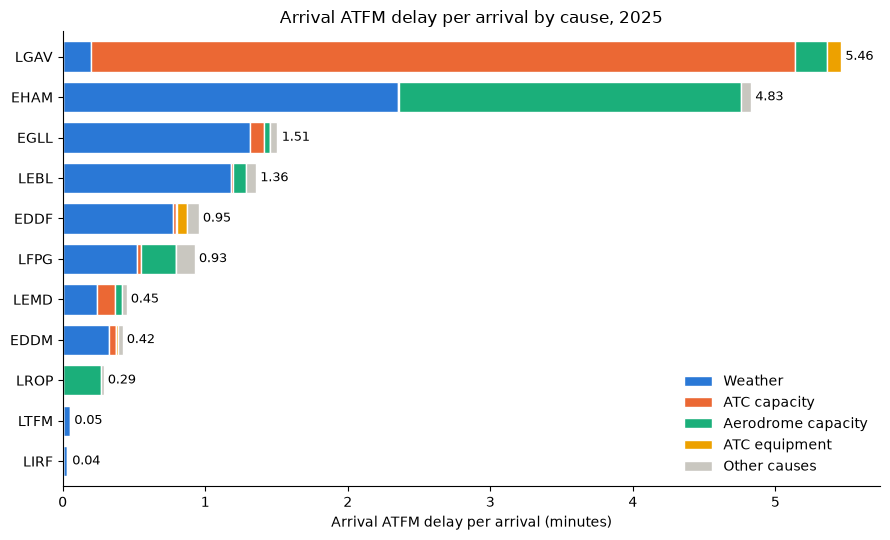

In [28]:
top = by_cause.sum().nlargest(4).index          # 4 biggest causes, the rest grouped as "Other causes"
plot_df = by_cause[top].assign(**{"Other causes": by_cause.drop(columns=top).sum(axis=1)})
plot_df = plot_df.loc[plot_df.sum(axis=1).sort_values().index]

colors = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#c9c7c0"]
ax = plot_df.plot.barh(stacked=True, figsize=(9, 5.5), color=colors, width=0.75,
                       edgecolor="white", linewidth=1)
for i, total in enumerate(plot_df.sum(axis=1)):
    ax.text(total + 0.03, i, f"{total:.2f}", va="center", fontsize=9)
ax.set_xlabel("Arrival ATFM delay per arrival (minutes)")
ax.set_ylabel("")
ax.set_title("Arrival ATFM delay per arrival by cause, 2025")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="lower right")
plt.tight_layout()
plt.savefig(IMAGES / "arrival_delay_by_cause_2025.png", dpi=150)
plt.show()

### What this shows

Athens had the most arrival ATFM delay in 2025, 5.5 minutes per arrival, and almost all of it (4.9 min) was coded ATC capacity. That points to an approach/TMA capacity problem rather than weather. Amsterdam is close behind (4.8 min), but there it splits roughly half and half between weather and aerodrome capacity, which fits Schiphol's runway configuration being sensitive to wind. At most other hubs the delay is smaller and mainly weat
her. Rome and Istanbul have almost no arrival ATFM delay at all.

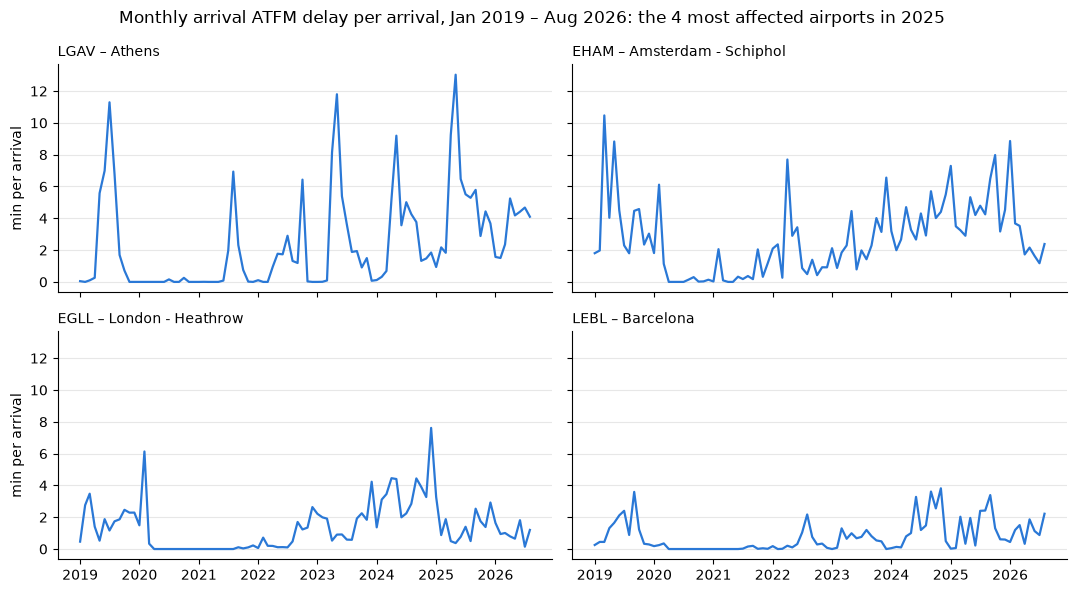

In [29]:
monthly = daily.groupby(["APT_ICAO", pd.Grouper(key="FLT_DATE", freq="MS")])[["DLY_APT_ARR_1", "FLT_ARR_1"]].sum()
monthly["dly_per_arr"] = monthly["DLY_APT_ARR_1"] / monthly["FLT_ARR_1"]
trend = monthly["dly_per_arr"].unstack("APT_ICAO")

worst4 = plot_df.sum(axis=1).nlargest(4).index    # the 4 most delayed airports in 2025
names = daily.drop_duplicates("APT_ICAO").set_index("APT_ICAO")["APT_NAME"]

fig, axes = plt.subplots(2, 2, figsize=(11, 6), sharex=True, sharey=True)
for ax, apt in zip(axes.flat, worst4):
    ax.plot(trend.index, trend[apt], color="#2a78d6", linewidth=1.6)
    ax.set_title(f"{apt} – {names[apt]}", fontsize=10, loc="left")
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", alpha=0.3)
for ax in axes[:, 0]:
    ax.set_ylabel("min per arrival")
fig.suptitle("Monthly arrival ATFM delay per arrival, Jan 2019 – Aug 2026: the 4 most affected airports in 2025")
plt.tight_layout()
plt.savefig(IMAGES / "monthly_trend_top4.png", dpi=150)
plt.show()

### What this shows

Delay almost disappeared in 2020–2021 (COVID) and came back from 2022 with traffic. Athens shows a clear spike every spring and summer, peaking in May 2025 at 13 minutes per arrival. Amsterdam is high all year rather than only in summer. 2025 was the worst year for Athens and Amsterdam, and 2024 for Heathrow. Comparing the same months (Jan–Aug), 2026 improved: Athens fell from 6.1 to 3.8 min per arrival and Amsterdam from 4.4 to 2.9, while Barcelona stayed about the same.

## 11. Q2 continued: when is arrival ATFM delay worst?

To compare months, weekdays and traffic levels fairly, I use the full "normal" years only: 2019 and 2022–2025. I leave out 2020–2021 (COVID, almost no delay) and 2026 (only January–August, so it would over-weight spring and summer).

In [30]:
COMPARE_YEARS = [2019, 2022, 2023, 2024, 2025]
normal = daily[daily["year"].isin(COMPARE_YEARS)].copy()
normal["month"] = normal["FLT_DATE"].dt.month
normal["weekday"] = normal["FLT_DATE"].dt.dayofweek      # 0 = Monday ... 6 = Sunday

order = plot_df.sum(axis=1).sort_values(ascending=False).index   # most delayed airport (2025) on top

The airports differ a lot in size of delay (Athens ~5 min per arrival, Rome ~0.05), so one shared colour scale would leave most rows white. This helper colours each row relative to its own worst value (dark = that airport's worst month/weekday), while the number in each cell is the real value in minutes per arrival.

For airports with almost no ATFM delay (Rome, Istanbul, Bucharest) the colours exaggerate tiny differences (0.1 vs 0.2 min), so read those rows from the numbers, not the colours.

In [31]:
def heatmap(grid, title, xlabels, filename):
    """Colour = each row relative to its own maximum; number in the cell = real value."""
    row_max = grid.max(axis=1).replace(0, float("nan"))   # avoid dividing by 0
    relative = grid.div(row_max, axis=0).fillna(0)

    fig, ax = plt.subplots(figsize=(10, 5.5))
    ax.imshow(relative.values, cmap="Blues", aspect="auto", vmin=0, vmax=1)
    ax.set_xticks(range(grid.shape[1]), xlabels)
    ax.set_yticks(range(grid.shape[0]), grid.index)
    for i in range(grid.shape[0]):
        for j in range(grid.shape[1]):
            ax.text(j, i, f"{grid.values[i, j]:.1f}", ha="center", va="center", fontsize=8,
                    color="white" if relative.values[i, j] > 0.6 else "black")
    ax.set_title(title)
    plt.tight_layout()
    plt.savefig(IMAGES / filename, dpi=150)
    plt.show()

### Season

All 11 airports together, minutes per arrival by month:
month
1     0.87
2     0.69
3     1.14
4     1.18
5     1.77
6     1.31
7     1.39
8     1.08
9     1.45
10    1.35
11    1.16
12    1.39


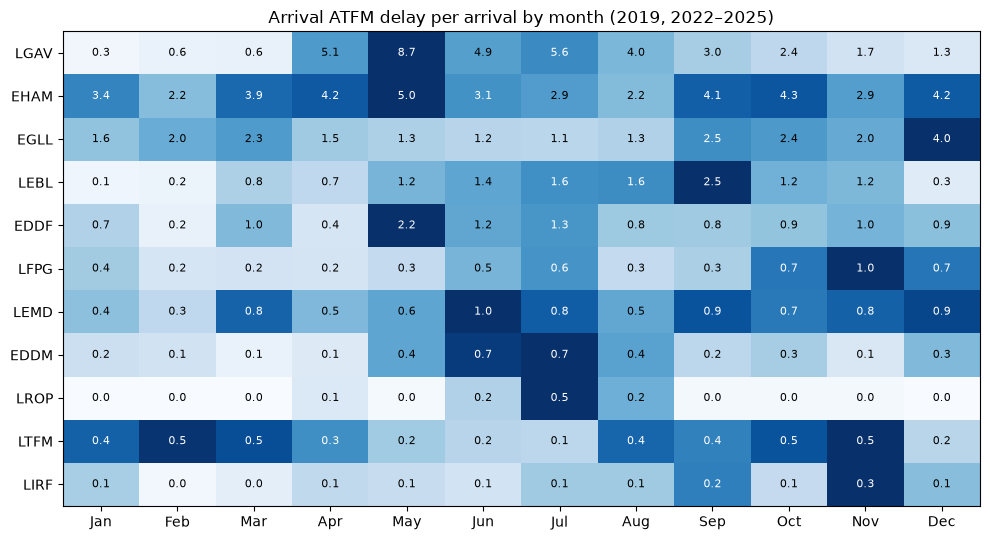

In [32]:
by_month = rate(normal, "DLY_APT_ARR_1", "FLT_ARR_1", ["APT_ICAO", "month"]).unstack("month").loc[order]
network_month = rate(normal, "DLY_APT_ARR_1", "FLT_ARR_1", "month")
print("All 11 airports together, minutes per arrival by month:")
print(network_month.round(2).to_string())

MONTHS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
heatmap(by_month, "Arrival ATFM delay per arrival by month (2019, 2022–2025)", MONTHS, "seasonality_heatmap.png")

### What this shows

Across the 11 airports, May is the worst month (1.8 min per arrival) and February the best (0.7). The peak is not the same everywhere. Athens is a spring/summer problem (April–August, 8.7 min in May), while Heathrow peaks in December (4.0) and in September–October, which points to winter weather. Barcelona peaks in September, and Amsterdam is high in most months. So a single "summer peak" story would be wrong: each airport has its own season, depending on whether its delay comes from capacity or from weather.

### Weekday

All 11 airports together, minutes per arrival by weekday (0 = Monday):
weekday
0    1.38
1    1.04
2    1.17
3    1.34
4    1.49
5    1.11
6    1.22


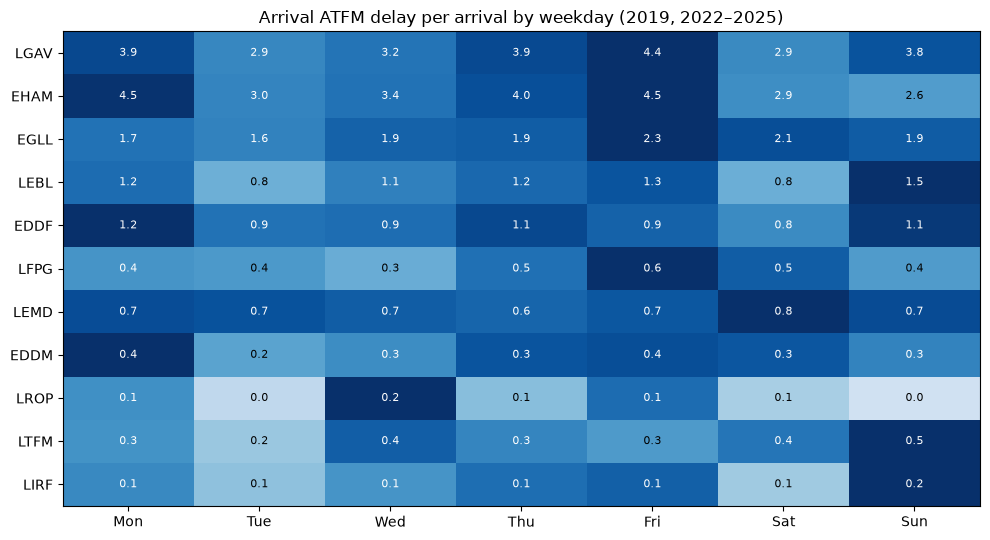

In [33]:
by_weekday = rate(normal, "DLY_APT_ARR_1", "FLT_ARR_1", ["APT_ICAO", "weekday"]).unstack("weekday").loc[order]
network_weekday = rate(normal, "DLY_APT_ARR_1", "FLT_ARR_1", "weekday")
print("All 11 airports together, minutes per arrival by weekday (0 = Monday):")
print(network_weekday.round(2).to_string())

DAYS = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
heatmap(by_weekday, "Arrival ATFM delay per arrival by weekday (2019, 2022–2025)", DAYS, "weekday_heatmap.png")

### What this shows

Friday (1.5 min per arrival) and Monday (1.4) are the worst days, and Tuesday (1.0) and Saturday (1.1) the best. The pattern is strongest at Amsterdam (4.5 min on Monday and Friday vs 2.6 on Sunday) and Athens (4.4 on Friday). This matches airline schedules: Friday and Monday are the busiest days (most arrivals on average) because of business and weekend traffic, while Saturday is the quietest.

### Traffic level

Is delay higher on busy days? Within **each airport and year**, I split the days into 5 equal groups by number of arrivals, from the quietest 20% to the busiest 20%. Comparing each airport with itself (and within the same year) removes the effect of airport size and of traffic growth over the years.

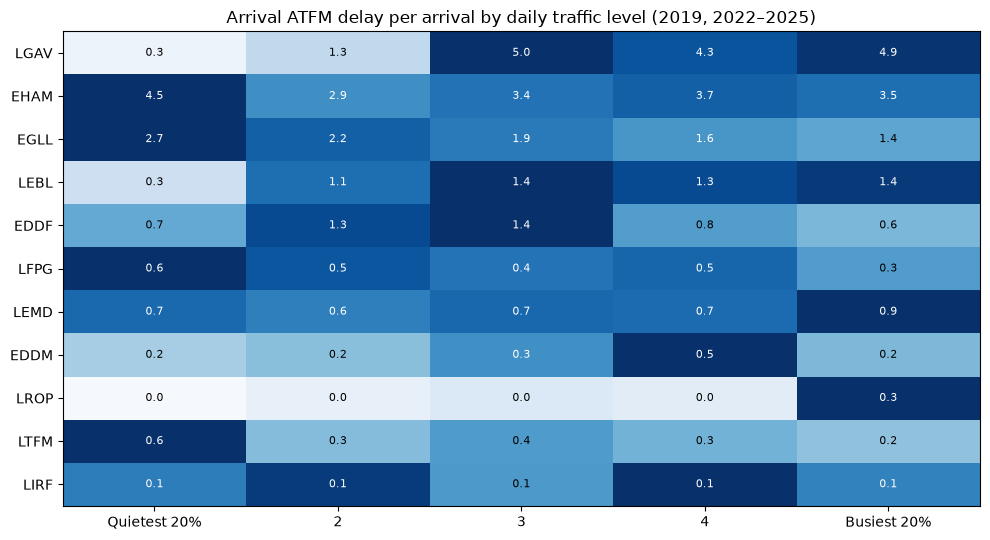

In [34]:
TRAFFIC_LEVELS = ["1 quietest", "2", "3", "4", "5 busiest"]
normal["traffic_level"] = (normal.groupby(["APT_ICAO", "year"])["FLT_ARR_1"]
                           .transform(lambda s: pd.qcut(s.rank(method="first"), 5, labels=TRAFFIC_LEVELS))
                           .astype(str))

by_traffic = rate(normal, "DLY_APT_ARR_1", "FLT_ARR_1", ["APT_ICAO", "traffic_level"]).unstack("traffic_level").loc[order]
heatmap(by_traffic, "Arrival ATFM delay per arrival by daily traffic level (2019, 2022–2025)",
        ["Quietest 20%", "2", "3", "4", "Busiest 20%"], "traffic_level_heatmap.png")

**Careful reading:** traffic and delay influence each other. On a day with heavy weather, airlines cancel flights, so the day has *fewer* arrivals *and* more delay. That is why, for an airport like Heathrow, the "quietest" days can show the most delay. A pattern here is a correlation, not proof that traffic causes delay.

### What this shows

At Athens and Barcelona, delay rises clearly with traffic. Athens goes from 0.3 min per arrival on its quietest days to about 5 on busy days, and Barcelona from 0.3 to 1.4, which points to capacity-limited airports. Bucharest only gets delay on its busiest 20% of days (0.3 min). Heathrow, Amsterdam, Paris and Istanbul show the opposite: they have the most delay on their *quietest* days (Heathrow 2.7 vs 1.4 min). This is most likely because bad weather causes both the delay and the cancellations that make those days look "quiet".

Part of the Athens pattern is also seasonal. Its busiest days are summer days, when its ATC capacity problem peaks. So traffic, season and weather are mixed together here, and this chart shows a correlation, not a cause.

## 12. Q3: Does ATFM slot adherence get worse when delay is high?

When the Network Manager regulates a flight, it gets a take-off slot (CTOT). The flight should take off within a tolerance window of **−5 to +10 minutes** around it. The slot adherence file counts, per airport and day:

- `FLT_DEP_REG_1`: regulated departures (flights with a slot)
- `FLT_DEP_OUT_EARLY_1` / `FLT_DEP_IN_1` / `FLT_DEP_OUT_LATE_1`: of those, how many took off early, inside the window, or late

**Slot adherence = take-offs inside the window ÷ regulated departures.** Early + inside + late always add up to the regulated departures; check it:

In [35]:
check = slot["FLT_DEP_OUT_EARLY_1"] + slot["FLT_DEP_IN_1"] + slot["FLT_DEP_OUT_LATE_1"] - slot["FLT_DEP_REG_1"]
print("rows where early + in + late != regulated:", (check != 0).sum())

rows where early + in + late != regulated: 0


### Adherence per airport and year

The `rate()` function works here too: "minutes" can be any count, so `rate(df, "FLT_DEP_IN_1", "FLT_DEP_REG_1", ...)` gives the share of regulated flights inside the window.

In [36]:
adherence = (rate(daily, "FLT_DEP_IN_1", "FLT_DEP_REG_1", ["APT_ICAO", "year"]) * 100).unstack("year")
regulated = (rate(daily, "FLT_DEP_REG_1", "FLT_DEP_1", ["APT_ICAO", "year"]) * 100).unstack("year")
print("Slot adherence, % of regulated departures inside the window")
display(adherence.round(1))
print("Regulated departures, % of all departures")
display(regulated.round(1))

Slot adherence, % of regulated departures inside the window


year,2019,2020,2021,2022,2023,2024,2025,2026
APT_ICAO,,,,,,,,
EDDF,93.5,92.3,96.4,96.4,96.3,97.1,97.8,97.4
EDDM,94.8,94.3,96.9,97.6,95.1,95.6,95.5,95.5
EGLL,97.7,98.4,99.3,99.3,99.1,98.7,98.3,98.3
EHAM,97.1,97.6,98.1,97.7,98.4,98.7,98.6,98.6
LEBL,96.7,94.9,98.7,99.0,99.2,99.3,99.4,99.5
LEMD,95.5,94.2,96.6,97.4,97.1,97.4,97.8,98.5
LFPG,94.9,95.4,94.7,93.9,94.9,95.9,95.3,96.5
LGAV,93.3,94.5,93.9,94.7,94.4,92.4,92.5,92.3
LIRF,94.8,98.0,98.1,96.5,95.5,93.1,94.8,94.7


Regulated departures, % of all departures


year,2019,2020,2021,2022,2023,2024,2025,2026
APT_ICAO,,,,,,,,
EDDF,31.6,5.0,6.9,29.4,32.4,32.4,30.8,28.2
EDDM,29.1,7.1,6.4,28.3,34.8,32.5,31.8,27.1
EGLL,20.5,5.1,5.0,20.6,24.6,23.1,23.3,23.6
EHAM,24.1,5.3,7.3,23.2,24.9,25.0,24.0,21.4
LEBL,25.5,7.7,5.7,16.4,22.9,28.0,32.2,36.9
LEMD,20.8,7.4,4.5,13.9,20.7,24.3,26.5,28.6
LFPG,22.6,8.5,8.4,21.1,32.3,31.7,26.5,28.2
LGAV,21.8,2.1,8.8,17.5,21.7,23.9,19.8,34.5
LIRF,20.2,4.3,6.9,19.5,22.9,27.4,26.2,27.3


### Network view: days with many regulations

Using **all** airports in the file, from 2022: I split the days into 5 groups by how many departures were regulated (a measure of how much ATFM pressure the network was under that day), and compare adherence across the groups.

In [37]:
SLOT_COLS = ["FLT_DEP_1", "FLT_DEP_REG_1", "FLT_DEP_OUT_EARLY_1", "FLT_DEP_IN_1", "FLT_DEP_OUT_LATE_1"]
net = slot[slot["FLT_DATE"] >= "2022-01-01"].groupby("FLT_DATE")[SLOT_COLS].sum()
net["regulated_pct"] = net["FLT_DEP_REG_1"] / net["FLT_DEP_1"] * 100

PRESSURE = ["1 fewest regulations", "2", "3", "4", "5 most regulations"]
net["pressure"] = pd.qcut(net["regulated_pct"], 5, labels=PRESSURE).astype(str)

g = net.groupby("pressure")[SLOT_COLS].sum()
pd.DataFrame({
    "regulated % of departures": g["FLT_DEP_REG_1"] / g["FLT_DEP_1"] * 100,
    "inside window %": g["FLT_DEP_IN_1"] / g["FLT_DEP_REG_1"] * 100,
    "early %": g["FLT_DEP_OUT_EARLY_1"] / g["FLT_DEP_REG_1"] * 100,
    "late %": g["FLT_DEP_OUT_LATE_1"] / g["FLT_DEP_REG_1"] * 100,
}).round(1)

,regulated % of departures,inside window %,early %,late %
pressure,,,,
1 fewest regulations,7.4,94.5,3.4,2.0
2,15.8,95.0,3.1,1.9
3,24.7,94.9,3.0,2.1
4,33.7,94.9,2.9,2.1
5 most regulations,43.8,95.0,2.9,2.1


### Airport view: each airport's worst-delay days

The network view measures how many flights are regulated, not how much delay there is. So I also look at each airport separately: I split its days (2022 onwards) into 5 groups by **total pre-departure delay per departure**, from the calmest 20% to the worst 20%, and compare slot adherence on those days.

In [38]:
q3 = daily[daily["year"] >= 2022].dropna(subset=["DLY_ALL_PRE_2", "FLT_DEP_IFR_2", "FLT_DEP_REG_1"])
q3 = q3[(q3["FLT_DEP_IFR_2"] > 0) & (q3["FLT_DEP_REG_1"] > 0)].copy()
q3["pre_dly_per_dep"] = q3["DLY_ALL_PRE_2"] / q3["FLT_DEP_IFR_2"]

DELAY_LEVELS = ["1 calmest", "2", "3", "4", "5 worst"]
q3["delay_level"] = (q3.groupby("APT_ICAO")["pre_dly_per_dep"]
                     .transform(lambda s: pd.qcut(s, 5, labels=DELAY_LEVELS))
                     .astype(str))

in_window = (rate(q3, "FLT_DEP_IN_1", "FLT_DEP_REG_1", ["APT_ICAO", "delay_level"]) * 100).unstack()
late = (rate(q3, "FLT_DEP_OUT_LATE_1", "FLT_DEP_REG_1", ["APT_ICAO", "delay_level"]) * 100).unstack()
print("All 11 airports together:")
print(pd.DataFrame({
    "pre-dep delay per departure (min)": rate(q3, "DLY_ALL_PRE_2", "FLT_DEP_IFR_2", "delay_level"),
    "inside window %": rate(q3, "FLT_DEP_IN_1", "FLT_DEP_REG_1", "delay_level") * 100,
    "late %": rate(q3, "FLT_DEP_OUT_LATE_1", "FLT_DEP_REG_1", "delay_level") * 100,
}).round(1).to_string())
print("\nLate take-offs, % of regulated departures")
display(late.round(1))

All 11 airports together:
             pre-dep delay per departure (min)  inside window %  late %
delay_level                                                            
1 calmest                                  9.9             97.0     0.9
2                                         13.3             97.0     1.1
3                                         16.5             96.9     1.3
4                                         20.4             96.6     1.6
5 worst                                   31.0             95.6     2.2

Late take-offs, % of regulated departures


delay_level,1 calmest,2,3,4,5 worst
APT_ICAO,,,,,
EDDF,0.4,0.6,0.8,0.9,1.3
EDDM,0.2,0.4,0.5,0.6,0.7
EGLL,0.4,0.5,0.5,0.6,0.8
EHAM,0.7,0.7,0.9,1.2,1.7
LEBL,0.1,0.2,0.2,0.3,0.4
LEMD,0.2,0.3,0.3,0.4,0.5
LFPG,1.5,1.8,1.8,2.0,2.9
LGAV,0.7,1.1,2.1,2.8,4.0
LIRF,1.3,2.2,2.9,3.5,5.8


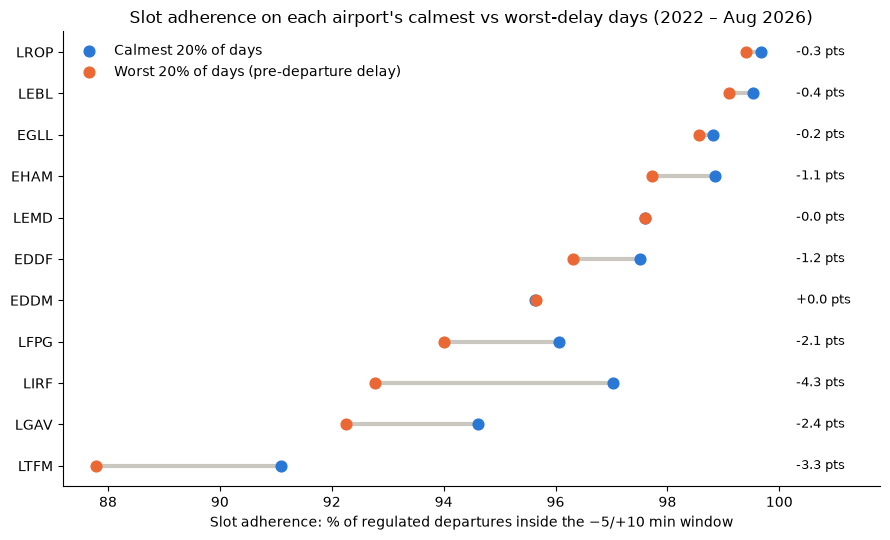

In [39]:
dumb = in_window[["1 calmest", "5 worst"]].sort_values("5 worst")

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.hlines(dumb.index, dumb["5 worst"], dumb["1 calmest"], color="#c9c7c0", linewidth=3)
ax.scatter(dumb["1 calmest"], dumb.index, color="#2a78d6", s=60, zorder=3, label="Calmest 20% of days")
ax.scatter(dumb["5 worst"], dumb.index, color="#eb6834", s=60, zorder=3, label="Worst 20% of days (pre-departure delay)")
for i, (apt, row) in enumerate(dumb.iterrows()):
    ax.text(100.3, i, f"{row['5 worst'] - row['1 calmest']:+.1f} pts", va="center", fontsize=9)
ax.set_xlim(right=101.8)
ax.set_xlabel("Slot adherence: % of regulated departures inside the −5/+10 min window")
ax.set_title("Slot adherence on each airport's calmest vs worst-delay days (2022 – Aug 2026)")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="upper left")
plt.tight_layout()
plt.savefig(IMAGES / "slot_adherence_calm_vs_worst.png", dpi=150)
plt.show()

### What this shows

Slot adherence does fall on bad days, but only moderately. Across the 11 airports it drops from 97.0% on the calmest 20% of days to 95.6% on the worst 20%, and almost all of the drop comes from **late** take-offs (0.9% → 2.2%), not early ones. The biggest falls are at Rome (−4.3 points), Istanbul (−3.3) and Athens (−2.4), while Bucharest, Heathrow and Barcelona barely change. Network-wide, days with many regulations do *not* have worse adherence (about 95% throughout), so the problem is disruption at the airport, not the number of slots.



## 13. Q4: Can we forecast arrival ATFM delay one week ahead?

**Task:** for each airport and day, predict the arrival ATFM delay per arrival **7 days in advance**. So the model may only use information that is at least 7 days old, plus things known in advance (weekday, month).

**Features** (the inputs to the model):
- `lag7`, `lag14`: delay on the same weekday 1 and 2 weeks earlier
- `avg_last_week`: average delay over the 7 days ending 7 days before
- `avg_last_4_weeks`: average delay over the 28 days ending 7 days before
- `arrivals_last_week`: arrivals on the same weekday a week earlier (a stand-in for planned traffic)
- `weekday`, `month`, `airport`

I don't use the actual number of arrivals on the day itself. On bad days flights get cancelled, so that number would quietly "leak" information about the delay the model is trying to predict.

**Train / test split by time:** train on 2022–2024, test on 2025 – Aug 2026. Training on the past and testing on the future is how the model would really be used. (A random split would let the model peek at days right next to the test days.)

In [40]:
from sklearn.ensemble import HistGradientBoostingRegressor, HistGradientBoostingClassifier
from sklearn.metrics import mean_absolute_error

fc = daily[daily["FLT_DATE"] >= "2021-06-01"].sort_values(["APT_ICAO", "FLT_DATE"]).copy()
# shift(7) means "7 rows earlier", which is only "7 days earlier" if no day is missing
assert (fc.groupby("APT_ICAO")["FLT_DATE"].diff().dropna() == pd.Timedelta(days=1)).all()

fc["delay"] = fc["DLY_APT_ARR_1"] / fc["FLT_ARR_1"]         # target: minutes per arrival

by_apt = fc.groupby("APT_ICAO")["delay"]
fc["lag7"] = by_apt.shift(7)
fc["lag14"] = by_apt.shift(14)
fc["avg_last_week"] = by_apt.transform(lambda s: s.shift(7).rolling(7).mean())
fc["avg_last_4_weeks"] = by_apt.transform(lambda s: s.shift(7).rolling(28).mean())
fc["arrivals_last_week"] = fc.groupby("APT_ICAO")["FLT_ARR_1"].shift(7)
fc["weekday"] = fc["FLT_DATE"].dt.dayofweek
fc["month"] = fc["FLT_DATE"].dt.month
fc["airport"] = fc["APT_ICAO"].astype("category").cat.codes  # airport as a number 0..10

FEATURES = ["lag7", "lag14", "avg_last_week", "avg_last_4_weeks", "arrivals_last_week",
            "weekday", "month", "airport"]
fc = fc.dropna(subset=FEATURES + ["delay"])

train = fc[(fc["FLT_DATE"] >= "2022-01-01") & (fc["FLT_DATE"] < "2025-01-01")]
test = fc[fc["FLT_DATE"] >= "2025-01-01"].copy()
print("train days:", len(train), "| test days:", len(test))
fc[["FLT_DATE", "APT_ICAO", "delay"] + FEATURES].tail()

train days: 12056 | test days: 6688


,FLT_DATE,APT_ICAO,delay,lag7,lag14,avg_last_week,avg_last_4_weeks,arrivals_last_week,weekday,month,airport
41778,2026-08-27,LTFM,0.0,0.0,0.0,0.0,0.0,823.0,3,8,10
41789,2026-08-28,LTFM,0.0,0.0,0.0,0.0,0.0,846.0,4,8,10
41800,2026-08-29,LTFM,0.0,0.0,0.0,0.0,0.0,846.0,5,8,10
41811,2026-08-30,LTFM,0.0,0.0,0.0,0.0,0.0,863.0,6,8,10
41822,2026-08-31,LTFM,0.0,0.0,0.0,0.0,0.0,840.0,0,8,10


**Baselines.** A model is only useful if it beats simple rules that need no machine learning. I compare it with three:
- *same day last week* (`lag7`)
- *average of the last 4 weeks* (`avg_last_4_weeks`)
- *always predict 0* (the typical day has no ATFM delay at all)

**Metric:** mean absolute error (MAE) = the average size of the error, in minutes per arrival. Lower is better.

**Model:** gradient boosting (`HistGradientBoostingRegressor`). It builds many small decision trees one after another, each one correcting the errors of the previous ones. `airport` is marked as a category, so the model treats it as a label, not as a number where 10 > 9.

In [41]:
model = HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05, max_depth=4,
                                      categorical_features=[FEATURES.index("airport")], random_state=0)
model.fit(train[FEATURES], train["delay"])
test["predicted"] = model.predict(test[FEATURES]).clip(min=0)   # delay can't be negative

results = pd.Series({
    "Same day last week": mean_absolute_error(test["delay"], test["lag7"]),
    "Always predict 0": mean_absolute_error(test["delay"], 0 * test["delay"]),
    "Average of last 4 weeks": mean_absolute_error(test["delay"], test["avg_last_4_weeks"]),
    "Gradient boosting model": mean_absolute_error(test["delay"], test["predicted"]),
}).sort_values(ascending=False)
results.round(3)

Same day last week         1.354
Always predict 0           1.292
Gradient boosting model    1.236
Average of last 4 weeks    1.202
dtype: float64

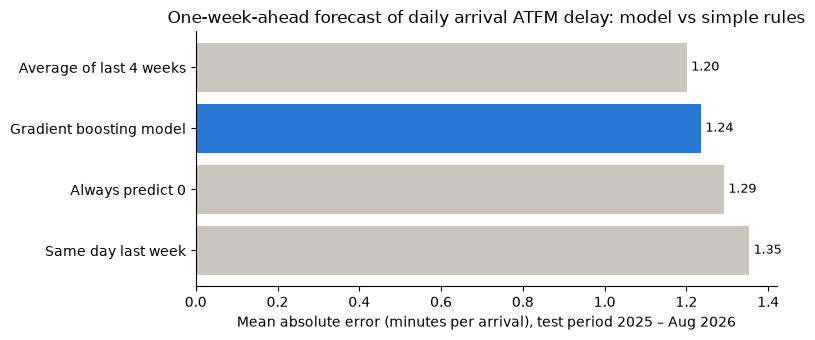

In [42]:
fig, ax = plt.subplots(figsize=(8, 3.5))
bar_colors = ["#2a78d6" if name == "Gradient boosting model" else "#c9c7c0" for name in results.index]
ax.barh(results.index, results.values, color=bar_colors)
for i, v in enumerate(results.values):
    ax.text(v + 0.01, i, f"{v:.2f}", va="center", fontsize=9)
ax.set_xlabel("Mean absolute error (minutes per arrival), test period 2025 – Aug 2026")
ax.set_title("One-week-ahead forecast of daily arrival ATFM delay: model vs simple rules")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(IMAGES / "forecast_mae.png", dpi=150)
plt.show()

### Forecasting "bad days" instead of exact minutes

For an airline, the exact number of minutes matters less than knowing **which days are likely to be bad**. So I also train a classifier: is the day a *high-delay day* (more than 2 minutes per arrival)? Then I take the 10% of test days each method flags as riskiest, and check how many of them really were high-delay days.

In [43]:
HIGH = 2   # minutes per arrival
train_high = (train["delay"] > HIGH).astype(int)
test["high"] = (test["delay"] > HIGH).astype(int)

clf = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, max_depth=4,
                                     categorical_features=[FEATURES.index("airport")], random_state=0)
clf.fit(train[FEATURES], train_high)
test["risk"] = clf.predict_proba(test[FEATURES])[:, 1]   # probability of a high-delay day

def hit_rate(score, share=0.10):
    """Of the `share` of days with the highest score, what % were really high-delay days?"""
    flagged = score.sort_values(ascending=False).index[: int(len(score) * share)]
    return test.loc[flagged, "high"].mean() * 100

print(f"High-delay days in the test period: {test['high'].mean() * 100:.1f}% of all days")
pd.Series({
    "Same day last week": hit_rate(test["lag7"]),
    "Average of last 4 weeks": hit_rate(test["avg_last_4_weeks"]),
    "Classifier": hit_rate(test["risk"]),
}, name="% of flagged days that were really high-delay").round(1)

High-delay days in the test period: 18.2% of all days


Same day last week         65.1
Average of last 4 weeks    80.5
Classifier                 87.4
Name: % of flagged days that were really high-delay, dtype: float64

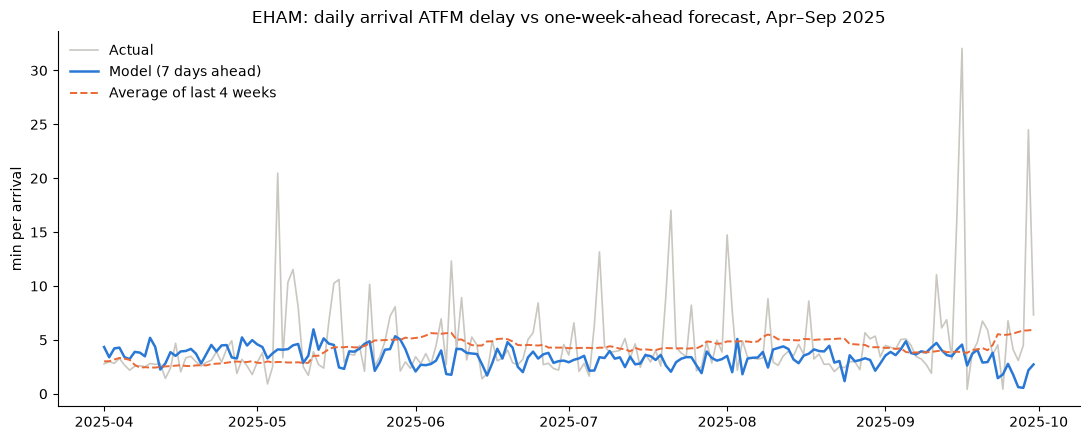

In [44]:
# Actual vs forecast for Amsterdam, summer 2025
apt = "EHAM"
view = test[(test["APT_ICAO"] == apt) & test["FLT_DATE"].between("2025-04-01", "2025-09-30")]

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(view["FLT_DATE"], view["delay"], color="#c9c7c0", linewidth=1.2, label="Actual")
ax.plot(view["FLT_DATE"], view["predicted"], color="#2a78d6", linewidth=1.8, label="Model (7 days ahead)")
ax.plot(view["FLT_DATE"], view["avg_last_4_weeks"], color="#eb6834", linewidth=1.4, linestyle="--",
        label="Average of last 4 weeks")
ax.set_ylabel("min per arrival")
ax.set_title(f"{apt}: daily arrival ATFM delay vs one-week-ahead forecast, Apr–Sep 2025")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
plt.tight_layout()
plt.savefig(IMAGES / "forecast_example_eham.png", dpi=150)
plt.show()

### What this shows


The model does not beat the simple rule for exact minutes: its error (about 1.24 min per arrival) is slightly worse than "average of the last 4 weeks" (1.20). Daily ATFM delay is driven by events like storms, strong wind and sudden capacity drops, which cannot be known a week ahead from past delay, so the model predicts the typical level and misses the spikes. Flagging risky days works better: of the 10% of days the classifier flagged, 87% really were high-delay days, against 81% for the 4-week average. For airline operations that is the more useful output, because it tells you when to plan extra buffer or reserves, not the exact minutes.

## 14. Limitations and future work

**Limitations**
- The code-89 share mixes two reporting sources (airlines for ATC delay, airport operators for total delay), so it is an estimate.
- IATA code 89 also includes some non-ATC reasons (e.g. late push-back approval), as EUROCONTROL notes.
- The data is daily per airport, so it can't show what happens to individual flights or rotations.
- No weather data is used, although weather is a main cause of arrival ATFM delay. That limits the forecast.

**Future work**
- Add weather (e.g. METAR/TAF) and planned traffic to the forecast.
- An interactive dashboard (Streamlit) to explore any airport.